In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import wandb


In [2]:
api = wandb.Api()

## Ablation Study


### GNN Architecture


In [3]:
runs = api.runs("liv4d/Topo-GNN", filters={"state": "finished", "config.EXP": "HP-Searchv4"})

In [4]:
data = []
for run in runs:
    summary = run.summary._json_dict
    run_data = {
        "name": run.name,
        "trial": run.config.get("TRIAL", None),
        "agg_acc": summary.get("val_agg", None),
        "dir_acc": summary.get("val_dir-acc", None),
        "av_acc": summary.get("val_av-acc", None),
        "parent_acc": summary.get("val_tree-parent-acc", None),
        "tags": run.tags,
    }
    data.append(run_data)
df = pd.DataFrame(data).sort_values(by="agg_acc", ascending=False)

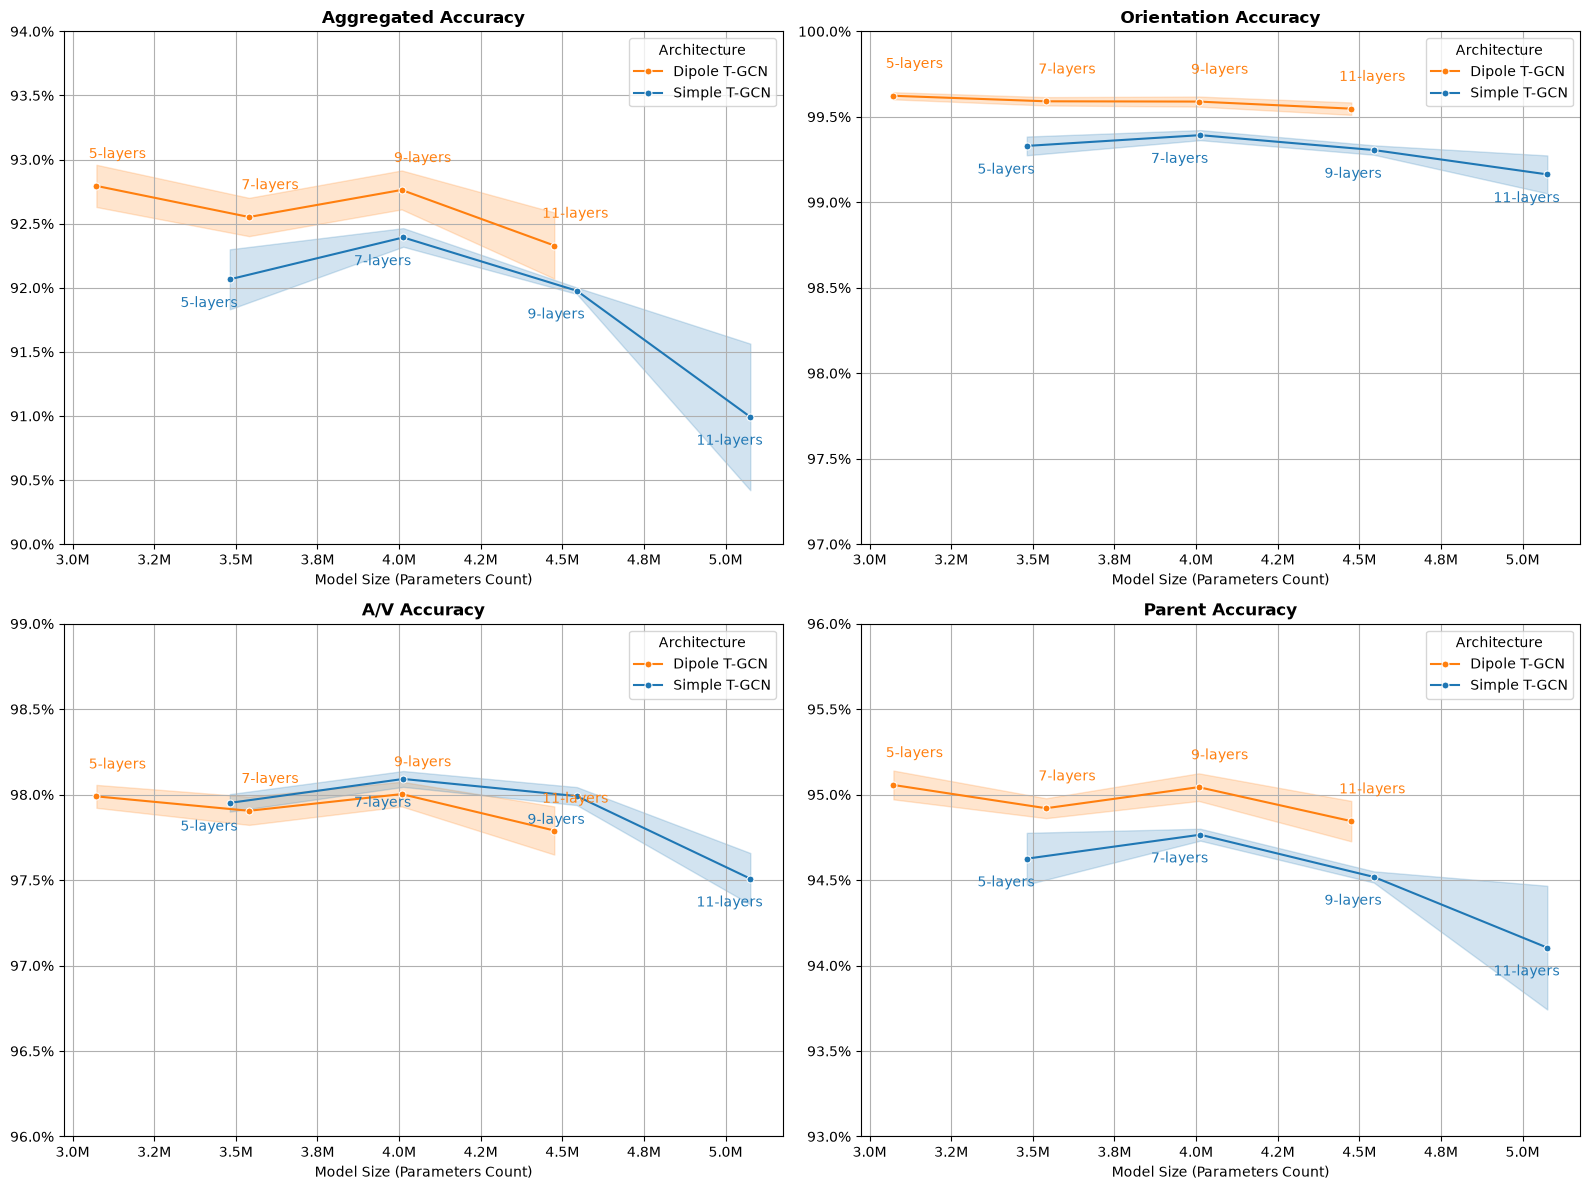

In [19]:
D = df.groupby("trial").head(4).copy()


def param_count(dipole, model):
    match model:
        case "shorter":
            return 3481604 if not dipole else 3073156
        case "short":
            return 4013060 if not dipole else 3540612
        case "medium":
            return 4544516 if not dipole else 4008068
        # case "medium-double":
        #    return 6772100 if not dipole else 5961156
        case "long":
            return 5075972 if not dipole else 4475524


D["dipole"] = D["trial"].map(lambda x: "bipole" in x)
D["model"] = D["trial"].map(lambda x: x.split("__", 1)[1].split("-", 1)[1])
D["Parameters Count"] = D.apply(lambda row: param_count(row["dipole"], row["model"]), axis=1)
D["Model"] = D["model"].map(
    {
        "shorter": "5-layers",
        "short": "7-layers",
        "medium": "9-layers",
        "medium-double": "9-layers Wide",
        "long": "11-layers",
    }
)
D["Architecture"] = D["dipole"].map({True: "Dipole T-GCN", False: "Simple T-GCN"})

D_mean = (
    D.groupby("trial")
    .agg(
        {m: "mean" for m in ["agg_acc", "dir_acc", "av_acc", "parent_acc"]}
        | {m: "first" for m in ["Parameters Count", "Model", "Architecture", "dipole"]}
    )
    .reset_index()
)


def plot(ax, y, ylabel, ylim: tuple[float, float] | None = None):
    COLORS = {"Simple T-GCN": "#1f77b4", "Dipole T-GCN": "#ff7f0e"}
    # Plot line plot of mean accuracy vs model size, one line for each architecture (dipole vs simple)
    # with error bars for the standard deviation, and label each point with the model name
    sns.lineplot(
        data=D,
        x="Parameters Count",
        y=y,
        hue="Architecture",
        marker=".",
        markersize=10,
        dashes=False,
        ax=ax,
        errorbar="sd",
        palette=COLORS,
    )

    # Add label with the model name above each point
    for i, row in D_mean.iterrows():
        ax.annotate(
            row["Model"],
            (row["Parameters Count"], row[y]),
            textcoords="offset points",
            xytext=(15, 20) if row["dipole"] else (-15, -20),
            ha="center",
            fontsize=10,
            color=COLORS[row["Architecture"]],
        )

    # Format x-axis ticks to be in engineering notation
    ax.set_xlabel("Model Size (Parameters Count)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: "{:.1f}M".format(x / 1e6)))
    ax.tick_params(axis="x", which="major", labelsize=10)
    # Format y-axis ticks to be in percentage
    ax.set_ylabel("")
    ax.set_title(ylabel, fontsize=12, fontweight="bold")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: "{:.1f}%".format(y * 100)))
    ax.tick_params(axis="y", which="major", labelsize=10)

    ax.grid()


fig, axs = plt.subplots(2, 2, figsize=(16, 12))
plot(axs[0, 0], "agg_acc", "Aggregated Accuracy", (0.9, 0.94))
plot(axs[0, 1], "dir_acc", "Orientation Accuracy", (0.97, 1))
plot(axs[1, 0], "av_acc", "A/V Accuracy", (0.96, 0.99))
plot(axs[1, 1], "parent_acc", "Parent Accuracy", (0.93, 0.96))
axs[0, 1].legend(title="Architecture")
fig.tight_layout()

### Data Aug

In [20]:
runs = api.runs("liv4d/Topo-GNN", filters={"state": "finished", "config.EXP": "DataAugAblation"})

In [21]:
data = []
for run in runs:
    summary = run.summary._json_dict
    run_data = {
        "name": run.name,
        "trial": run.config.get("TRIAL", None),
        "agg_acc": summary.get("val_agg", None),
        "dir_acc": summary.get("val_dir-acc", None),
        "av_acc": summary.get("val_av-acc", None),
        "parent_acc": summary.get("val_tree-parent-acc", None),
        "tags": run.tags,
    }
    data.append(run_data)
df = pd.DataFrame(data).sort_values(by="agg_acc", ascending=False)

/tmp/ipykernel_1700703/3982467402.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0, 1].legend(title="Architecture")


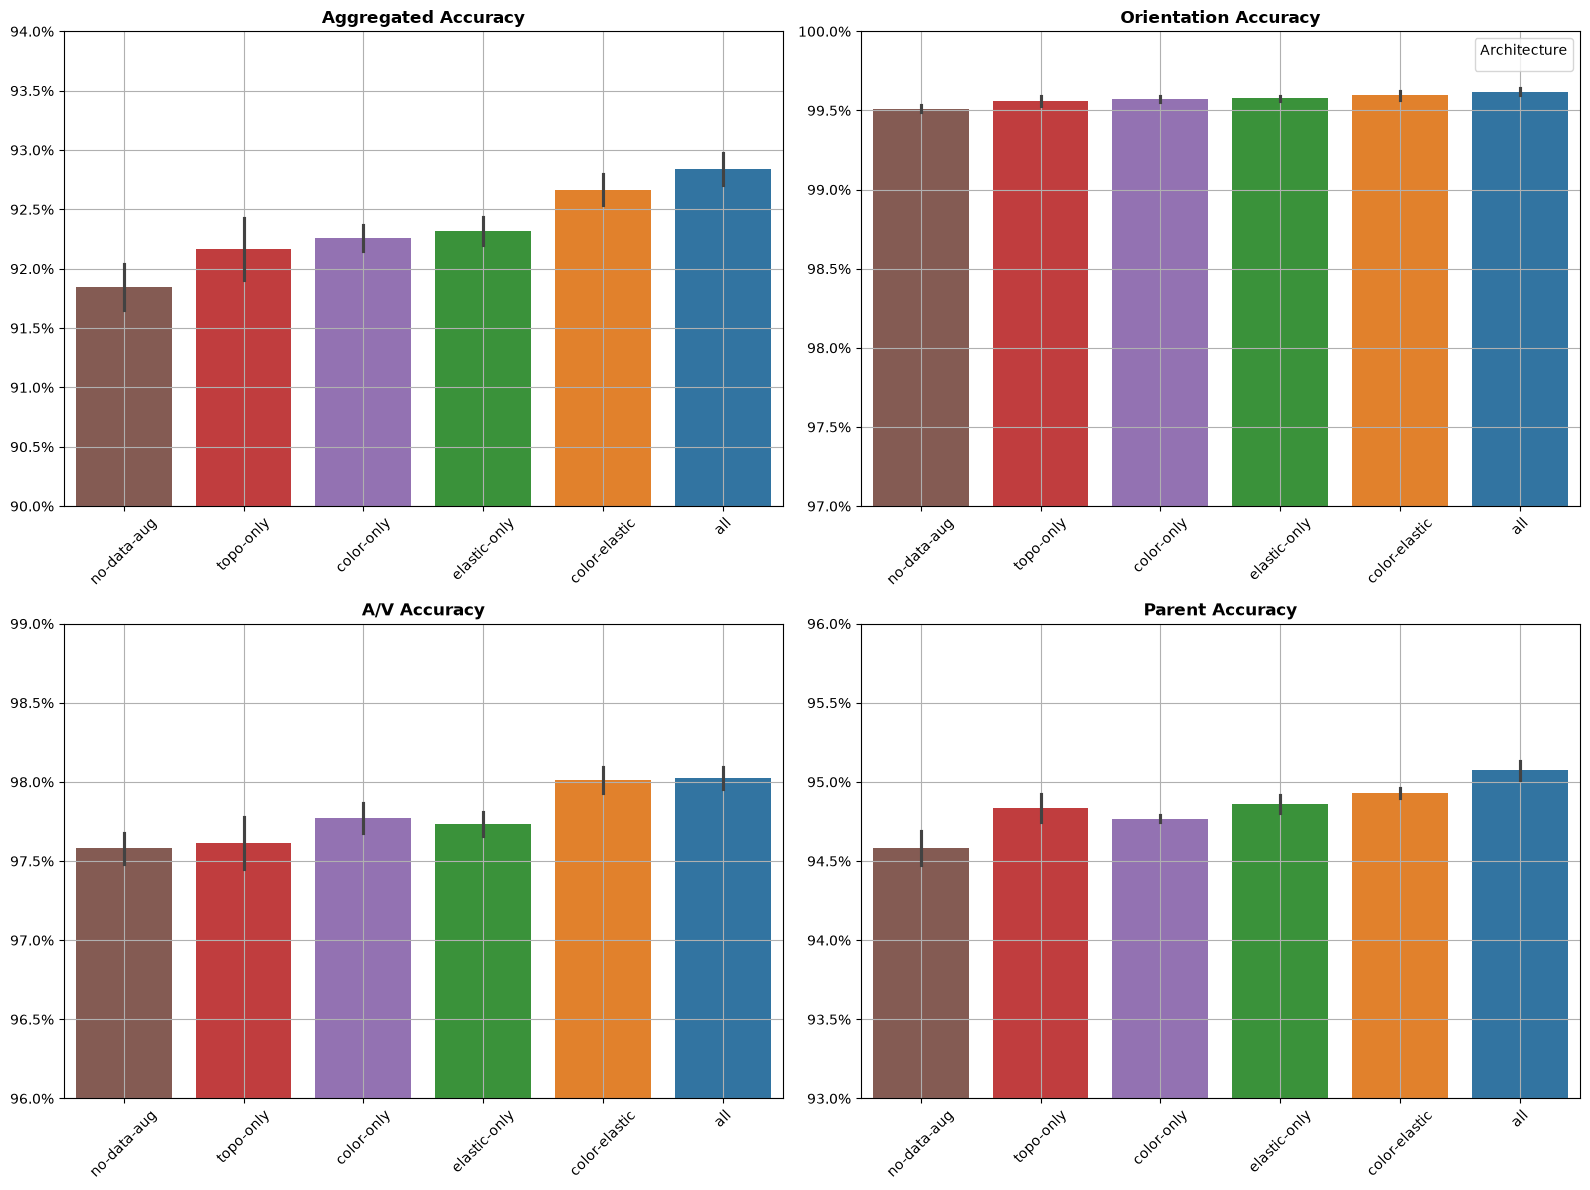

In [ ]:
D = df.groupby("trial").head(4).copy()
D["exp"] = D["trial"].str[17:]

D_mean = D.groupby("trial").agg({m: "mean" for m in ["agg_acc", "dir_acc", "av_acc", "parent_acc"]}).reset_index()


def plot(ax, y, ylabel, ylim: tuple[float, float] | None = None):
    COLORS = "#ff7f0e"
    # Plot line plot of mean accuracy vs model size, one line for each architecture (dipole vs simple)
    # with error bars for the standard deviation, and label each point with the model name
    sns.barplot(
        data=D,
        x="exp",
        hue="exp",
        order=["no-data-aug", "topo-only", "color-only", "elastic-only", "color-elastic", "all"],
        y=y,
        ax=ax,
        errorbar="sd",
    )

    # Format x-axis ticks to be sideways
    ax.set_xlabel("")
    ax.tick_params(axis="x", which="major", labelsize=10, rotation=45)

    # Format y-axis ticks to be in percentage
    ax.set_ylabel("")
    ax.set_title(ylabel, fontsize=12, fontweight="bold")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: "{:.1f}%".format(y * 100)))
    ax.tick_params(axis="y", which="major", labelsize=10)

    ax.grid()


fig, axs = plt.subplots(2, 2, figsize=(16, 12))
plot(axs[0, 0], "agg_acc", "Aggregated Accuracy", (0.9, 0.94))
plot(axs[0, 1], "dir_acc", "Orientation Accuracy", (0.97, 1))
plot(axs[1, 0], "av_acc", "A/V Accuracy", (0.96, 0.99))
plot(axs[1, 1], "parent_acc", "Parent Accuracy", (0.93, 0.96))
axs[0, 1].legend(title="Architecture")
fig.tight_layout()